# Improved Heterogeneous Graph Representation of Stiffened Panels

This walkthrough uses the **improved heterogeneous graph representation** from Paper 3, with four node types: `plate`, `force`, `edge`, and `Disp`.
The six boundary DOFs are concatenated into `Disp`. External loading remains separate.
The example is **Case 3**, the most complex three-cell box beam with double sides and hydrostatic loading. Each graph is one local stiffened panel extracted from that case. Only **32 real graphs** are bundled: 24 train, 4 validation, 4 test.

Paper 2 introduced and compared six representations. Paper 3, *A hybrid global–local computational framework for ship hull structural analysis using homogenized model and graph neural network* (Section 2.3.1), combines separate structural-edge and boundary-DOF node types with all six DOFs concatenated within each boundary node. This demo uses that improved representation and the full-size research HGT. It covers the local panel surrogate, rather than the full ESL global analysis and boundary-recovery pipeline.

Run this notebook from the repository directory, after installing `requirements.txt`.
All files are local; no dataset download or user-specific path is required.

In [1]:
from pathlib import Path
import json
import torch
import numpy as np
from IPython.display import display
from dataset import ROOT, load_dataset
from demo import load_checkpoint, evaluate, plot_prediction, train
%matplotlib inline
import matplotlib.pyplot as plt

torch.set_num_threads(4)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '| PyTorch:', torch.__version__)
graphs, splits, manifest = load_dataset()
print('Split sizes:', {name: len(values) for name, values in splits.items()})

Device: cuda | PyTorch: 2.7.1+cu126


Split sizes: {'train': 24, 'val': 4, 'test': 4}


## Construct a heterogeneous graph

`dataset.py` reads the CSV rows inside `data/case3_demo.zip`. Empty padding cells are removed, features are reshaped by node type, and connection endpoints are validated. Targets are stored on plate nodes and are **not** part of `x_dict`.

The ten loading features encode the pressure samples used by this Case 3 dataset. The two legacy cached `Disp ↔ edge` endpoint arrays were reversed during export to restore valid relation directions; features and target values were preserved.

In [2]:
graph = graphs[0]
print(graph)
print('Input dimensions:', dict(graph.num_node_features))
print('Relation types:', len(graph.edge_types))
assert graph.validate(raise_on_error=True)
assert set(graph.node_types) == {'plate', 'force', 'edge', 'Disp'}
assert graph['Disp'].x.shape[1] == 6 * 60

HeteroData(
  sample_id=0,
  plate={
    x=[9, 3],
    stress=[9, 500],
    U1=[9, 500],
    U2=[9, 500],
    U3=[9, 500],
    Location=[9, 4],
  },
  force={ x=[9, 10] },
  Disp={ x=[20, 360] },
  edge={ x=[28, 10] },
  (edge, e1, plate)={ edge_index=[2, 7] },
  (edge, e2, plate)={ edge_index=[2, 7] },
  (edge, e3, plate)={ edge_index=[2, 7] },
  (edge, e4, plate)={ edge_index=[2, 7] },
  (plate, e1, edge)={ edge_index=[2, 7] },
  (plate, e2, edge)={ edge_index=[2, 7] },
  (plate, e3, edge)={ edge_index=[2, 7] },
  (plate, e4, edge)={ edge_index=[2, 7] },
  (edge, e5, plate)={ edge_index=[2, 2] },
  (edge, e6, plate)={ edge_index=[2, 2] },
  (edge, e7, plate)={ edge_index=[2, 2] },
  (edge, e8, plate)={ edge_index=[2, 2] },
  (plate, e5, edge)={ edge_index=[2, 2] },
  (plate, e6, edge)={ edge_index=[2, 2] },
  (plate, e7, edge)={ edge_index=[2, 2] },
  (plate, e8, edge)={ edge_index=[2, 2] },
  (plate, e9, force)={ edge_index=[2, 9] },
  (force, e10, plate)={ edge_index=[2, 9] },
  (D

## Load the bundled pretrained model

The model has **ten HGT layers**, 64 hidden channels, four attention heads, and a final 500-channel HGT output layer: **4,887,056 trainable parameters**. It uses the original research checkpoint from zero-based epoch 480 as initialization, followed by additional training on the validated **4,800 Case 3 graphs**. The history shown later describes that additional phase, not a new training run from scratch. Only 24 training graphs are distributed.

BatchNorm shares the original affine parameters while preserving separate running moments for each node type. This retains the research training forward map and corrects inference-statistics mixing. Running moments are fitted using training data only and saved with the checkpoint. No additional input or stress-target rescaling is applied. Model selection uses the **200 validation graphs**.

The first report below is the full **999-graph** local test evaluation. The second report is recomputed from only the **four bundled test examples**. The later optional three-epoch training cell uses only the 24 released training graphs and is disabled by default.

In [3]:
model, checkpoint = load_checkpoint(ROOT / 'pretrained/case3_stress.pt', graph, device)
print('Parameters:', sum(p.numel() for p in model.parameters()))
print('Layers / hidden channels / heads / output channels:', 10, 64, 4, 500)
print('Weight file size (MiB):', (ROOT / 'pretrained/case3_stress.pt').stat().st_size / 2**20)
print('Best additional-training epoch:', checkpoint['best_epoch'])
print('Initialization:', checkpoint['provenance'])
print('Full 999-graph test report:')
print((ROOT / 'pretrained/full_test_metrics.json').read_text())
print('Recomputed four-example report:')
metrics, true, predicted = evaluate(model, splits['test'], device)
print(json.dumps(metrics, indent=2))

Parameters: 4887056
Layers / hidden channels / heads / output channels: 10 64 4 500
Weight file size (MiB): 18.840872764587402
Best additional-training epoch: 23
Initialization: Original 4800-graph research checkpoint (zero-based epoch 480), followed by 3 selected warm-start epochs and training-only per-node-type BN calibration
Full 999-graph test report:
{
  "rmse": 2.0470757484436035,
  "mae": 0.8984460234642029,
  "n_graphs": 999,
  "n_plate_nodes": 18631,
  "n_field_values": 9315500,
  "training_samples": 4800,
  "validation_samples": 200,
  "epochs_run": 25,
  "best_fine_tuning_epoch": 23,
  "source_research_epoch_zero_based": 480,
  "selected_warm_start_epochs": 3,
  "graph_rmse_median": 0.883951723575592,
  "graph_rmse_p90": 2.275933647155762,
  "training_elapsed_seconds": 1654.2339999999385,
  "parameter_count": 4887056,
  "checkpoint_bytes": 19756087,
  "best_validation_rmse": 1.7179683446884155,
  "stop_reason": "Convergence review: best validation RMSE improved by less than 

{
  "rmse": 1.16386878490448,
  "mae": 0.7182537317276001,
  "n_graphs": 4,
  "n_plate_nodes": 96,
  "n_field_values": 48000
}


## Reference, prediction, and error contours

Choose a test graph and plate using the zero-based indices below. Each plate has a 10 × 50 field grid. `order='F'` matches the original MATLAB column-major reshape. Coordinates are normalized local plate coordinates, not inferred global coordinates.

Original sample ID: 4800
Graph RMSE: 0.6277384161949158 MPa


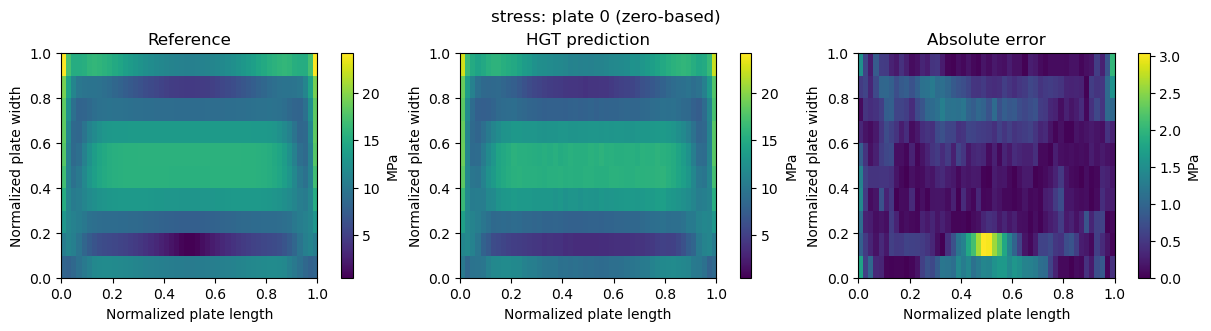

In [4]:
test_index = 0
plate_index = 0
sample = splits['test'][test_index]
sample_metrics, sample_true, sample_predicted = evaluate(model, [sample], device)
print('Original sample ID:', sample.sample_id)
print('Graph RMSE:', sample_metrics['rmse'], 'MPa')
fig = plot_prediction(sample_true, sample_predicted, plate=plate_index)
display(fig)
plt.close(fig)

## Compare field values and a representative path

The scatter uses every field value in the selected test graph. The path follows the middle row of the selected plate. The figures show the learned spatial response and remaining local errors.

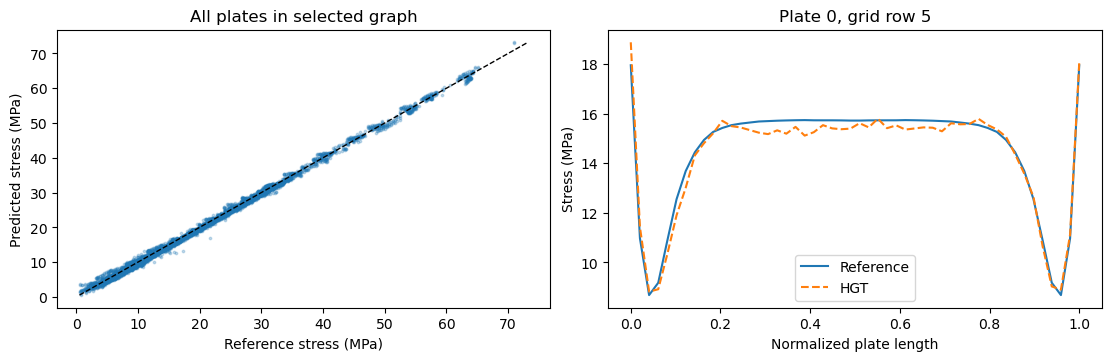

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].scatter(sample_true.ravel(), sample_predicted.ravel(), s=3, alpha=0.25)
lim = [min(sample_true.min(), sample_predicted.min()), max(sample_true.max(), sample_predicted.max())]
axes[0].plot(lim, lim, 'k--', linewidth=1)
axes[0].set(xlabel='Reference stress (MPa)', ylabel='Predicted stress (MPa)', title='All plates in selected graph')
truth_grid = sample_true[plate_index].reshape(10, 50, order='F')
pred_grid = sample_predicted[plate_index].reshape(10, 50, order='F')
x = np.linspace(0, 1, 50)
axes[1].plot(x, truth_grid[5], label='Reference')
axes[1].plot(x, pred_grid[5], '--', label='HGT')
axes[1].set(xlabel='Normalized plate length', ylabel='Stress (MPa)', title=f'Plate {plate_index}, grid row 5')
axes[1].legend()
display(fig)
plt.close(fig)

## Training history of the supplied checkpoint

Checkpoint selection uses validation MSE; the test set is used only for evaluation. The complete additional-training history is included. The original research initialization already represents training through zero-based epoch 480; those earlier epochs are not replayed in this curve.

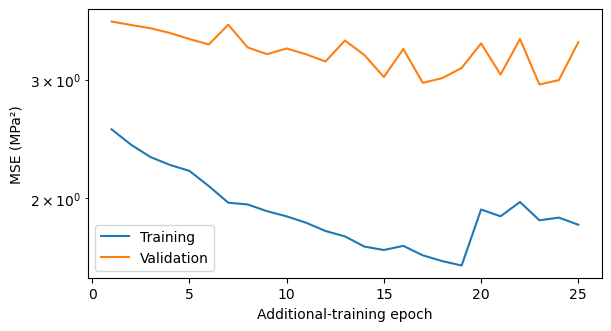

In [6]:
history = json.loads((ROOT / 'pretrained/training_history.json').read_text())
fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
for key, label in [('train_mse', 'Training'), ('val_mse', 'Validation')]:
    ax.semilogy([h['epoch'] for h in history], [h[key] for h in history], label=label)
ax.set(xlabel='Additional-training epoch', ylabel='MSE (MPa²)')
ax.legend()
display(fig)
plt.close(fig)

## Optional: train from scratch

The optional **three-epoch** run verifies optimization, validation, and checkpoint saving. It is **disabled by default**, does not overwrite the pretrained model, and is too short to establish prediction accuracy. Set `RUN_TRAINING=True` to run it. Reproducing the bundled weights requires the full training set and original initialization; the 24 released training examples are only a workflow example. GPU timings and exact floating-point results can vary.

`target` can also be `U1`, `U2`, or `U3`; displacement targets retain their stored research scaling.

In [7]:
RUN_TRAINING = False
if RUN_TRAINING:
    fresh_model, quick_history = train(splits, ROOT / 'outputs/notebook_training', device=device,
                                       epochs=3, case=manifest['case'])
    reloaded, saved = load_checkpoint(ROOT / 'outputs/notebook_training/best_model.pt', graph, device)
    with torch.no_grad():
        fresh_model.eval()
        reloaded.eval()
        check = sample.clone().to(device)
        a = fresh_model(check.x_dict, check.edge_index_dict)['plate']
        b = reloaded(check.x_dict, check.edge_index_dict)['plate']
        torch.testing.assert_close(a, b)
    print('Saved checkpoint reproduces the trained model predictions.')

## Scope

This release is a compact graph-construction, training, and inference example. It omits the full database, ablation variants, and other cases. The test errors above belong to this small release and do not reproduce the paper's full benchmark results. See `data/README.md` for sample provenance, scaling, and the corrected relation orientation.